In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 08 Robustness and regime analysis
All specifications are listed in `docs/experiment_log.md` and reported in full.

In [2]:
def piv(name, col, sharpe="sharpe"):
    d = pd.read_csv(OUT / "tables" / f"robustness_{name}.csv")
    return d.pivot(index="strategy_name", columns=col, values=sharpe).round(3)
print("Net Sharpe by transaction cost (bps)"); display(piv("cost", "cost_bps"))
print("by rebalance frequency"); display(piv("rebalance", "rebalance"))
print("by target volatility"); display(piv("target_vol", "target_vol"))
print("by training window"); display(piv("training_window", "training_window"))
print("by max weight"); display(piv("max_weight", "max_weight"))

Net Sharpe by transaction cost (bps)


cost_bps,0,5,10,25,50
strategy_name,,,,,
EqualWeight,0.566,0.565,0.564,0.561,0.556
MeanVariance,0.530,0.526,0.521,0.508,0.485
MinVariance,0.564,0.562,0.559,0.553,0.542
VolTarget_GARCH,0.629,0.622,0.615,0.596,0.563
VolTarget_HistVol,0.621,0.613,0.605,0.581,0.541
VolTarget_Oracle*,0.697,0.686,0.674,0.639,0.581
VolTarget_RF,0.605,0.599,0.594,0.577,0.548
VolTarget_XGB,0.593,0.586,0.578,0.556,0.520


by rebalance frequency


rebalance,monthly,quarterly,weekly
strategy_name,,,
EqualWeight,0.565,0.568,0.565
MeanVariance,0.526,0.528,0.517
MinVariance,0.562,0.554,0.561
VolTarget_GARCH,0.622,0.508,0.583
VolTarget_HistVol,0.613,0.511,0.571
VolTarget_Oracle*,0.686,0.504,0.990
VolTarget_RF,0.599,0.509,0.562
VolTarget_XGB,0.586,0.455,0.553


by target volatility


target_vol,0.08,0.10,0.12,0.15
strategy_name,,,,
EqualWeight,0.565,0.565,0.565,0.565
VolTarget_GARCH,0.625,0.622,0.616,0.610
VolTarget_HistVol,0.626,0.613,0.606,0.600
VolTarget_Oracle*,0.660,0.686,0.700,0.708
VolTarget_RF,0.595,0.599,0.595,0.579
VolTarget_XGB,0.576,0.586,0.580,0.556


by training window


training_window,504,756,1260
strategy_name,,,
EqualWeight,0.565,0.565,0.565
MeanVariance,0.540,0.540,0.540
MinVariance,0.569,0.569,0.569
VolTarget_GARCH,0.610,0.618,0.612
VolTarget_HistVol,0.607,0.607,0.607
VolTarget_Oracle*,0.683,0.683,0.683
VolTarget_RF,0.584,0.591,0.589


by max weight


max_weight,0.25,0.35,0.50
strategy_name,,,
MeanVariance,0.545,0.526,0.508
MinVariance,0.570,0.562,0.546


In [3]:
sp = pd.read_csv(OUT / "tables" / "robustness_subperiods.csv")
display(sp.pivot(index="strategy_name", columns="period", values="sharpe").round(2))
display(sp.pivot(index="strategy_name", columns="period", values="max_drawdown").round(2))

period,1993-2002,2003-2012,2013-2026,2022,COVID 2020-02 to 2020-06,GFC 2007-10 to 2009-06
strategy_name,,,,,,
EW_StaticMatched*,0.42,0.47,0.76,-0.54,-0.02,-0.51
EqualWeight,0.42,0.47,0.76,-0.54,-0.02,-0.51
MeanVariance,0.34,0.61,0.58,-0.57,-0.06,-0.46
MinVariance,0.43,0.61,0.61,-0.55,-0.27,-0.45
VolTarget_GARCH,0.50,0.61,0.72,-0.82,-0.46,-0.83
VolTarget_HistVol,0.46,0.63,0.71,-0.78,-1.11,-0.85
VolTarget_Oracle*,0.36,0.77,0.86,-1.03,-0.14,-0.78
VolTarget_RF,0.55,0.54,0.67,-1.21,-0.20,-0.93
VolTarget_XGB,0.56,0.51,0.66,-1.24,-0.38,-0.90


period,1993-2002,2003-2012,2013-2026,2022,COVID 2020-02 to 2020-06,GFC 2007-10 to 2009-06
strategy_name,,,,,,
EW_StaticMatched*,-0.28,-0.43,-0.29,-0.14,-0.29,-0.43
EqualWeight,-0.36,-0.53,-0.37,-0.18,-0.37,-0.53
MeanVariance,-0.29,-0.39,-0.32,-0.19,-0.32,-0.39
MinVariance,-0.30,-0.39,-0.34,-0.18,-0.34,-0.39
VolTarget_GARCH,-0.23,-0.25,-0.15,-0.10,-0.14,-0.25
VolTarget_HistVol,-0.24,-0.24,-0.20,-0.11,-0.20,-0.23
VolTarget_Oracle*,-0.28,-0.22,-0.16,-0.14,-0.12,-0.21
VolTarget_RF,-0.19,-0.28,-0.18,-0.13,-0.18,-0.28
VolTarget_XGB,-0.18,-0.28,-0.16,-0.12,-0.16,-0.28


In [4]:
st_ = pd.read_csv(OUT / "tables" / "robustness_stress_threshold.csv")
st_[st_.strategy_name.isin(["EqualWeight", "VolTarget_GARCH", "VolTarget_RF"])].pivot_table(
    index=["strategy_name", "regime"], columns="vix_threshold", values="sharpe").round(2)

vix_threshold             20    25    30
strategy_name   regime                  
EqualWeight     calm    0.59  0.59  0.58
                stress  0.63  0.68  0.76
VolTarget_GARCH calm    0.56  0.58  0.57
                stress  0.72  0.78  1.02
VolTarget_RF    calm    0.55  0.59  0.57
                stress  0.67  0.68  0.87

In [5]:
pd.read_csv(OUT / 'tables' / 'robustness_forecast_training_window.csv').pivot(index='model', columns='training_window', values='QLIKE').round(3)

training_window,504,756,1260
model,,,
garch,0.396,0.389,0.393
historical_vol,0.464,0.464,0.464
random_forest,0.414,0.404,0.383


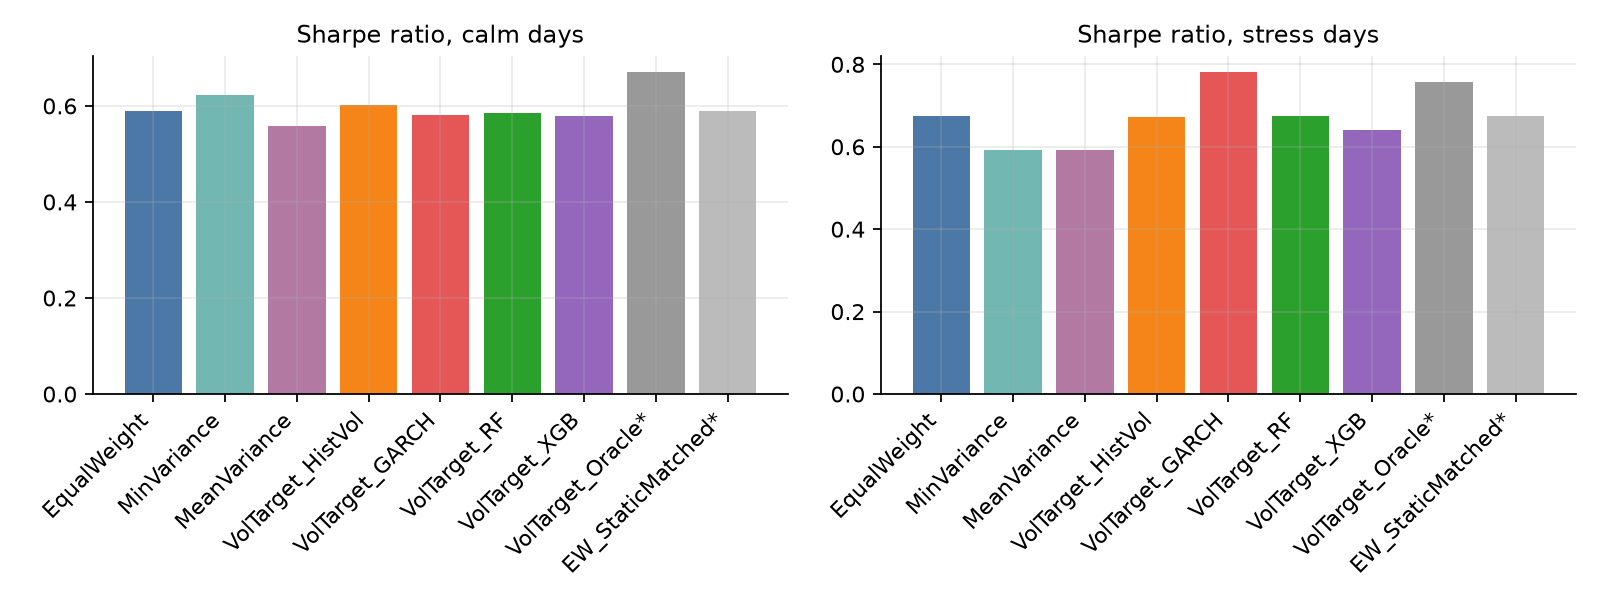

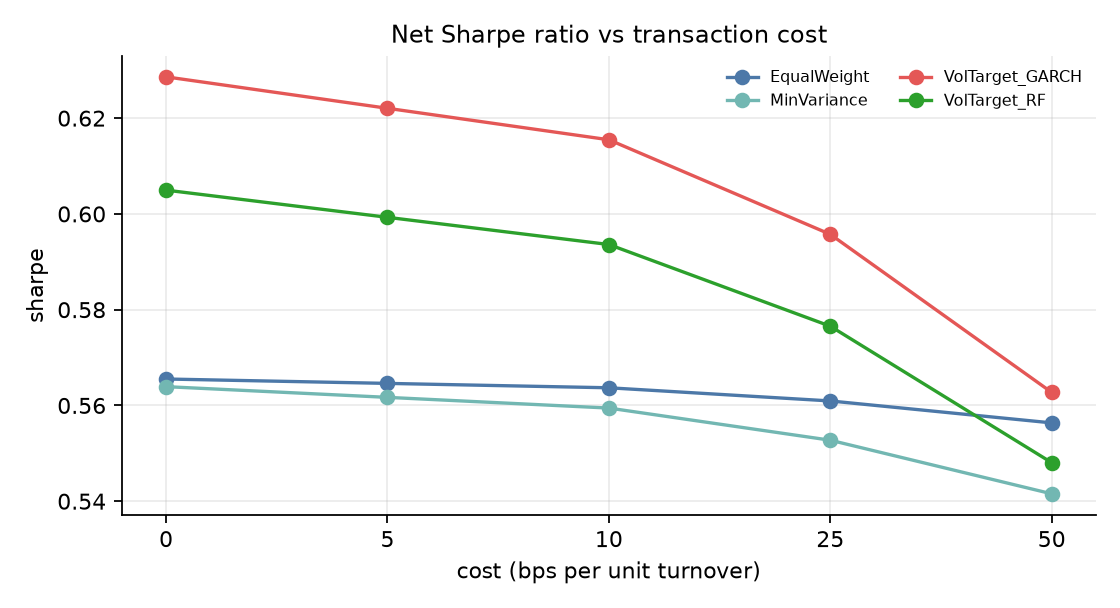

In [6]:
show('fig_regime_sharpe'); show('fig_cost_sensitivity')